### Se tiene 2 archivos, conductores con algunos atributos y un log con sus recorridos.
### ¿Como encontramos los 10 conductores que mas han recorrido en el año?


In [1]:
import sqlite3

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
 

In [2]:
# Carga de la tabla drivers

drivers = pd.read_csv(
    "../data/drivers.csv",
    sep=",",
    thousands=None,
    decimal=".",
)
drivers.head()



,driverId,name,ssn,location,certified,wage-plan
0,10,George Vetticaden,621011971,244-4532 Nulla Rd.,N,miles
1,11,Jamie Engesser,262112338,366-4125 Ac Street,N,miles
2,12,Paul Coddin,198041975,Ap #622-957 Risus. Street,Y,hours
3,13,Joe Niemiec,139907145,2071 Hendrerit. Ave,Y,hours
4,14,Adis Cesir,820812209,Ap #810-1228 In St.,Y,hours


In [12]:
# Carga de la tabla timesheet
timesheet = pd.read_csv(
    "../data/timesheet.csv",
    sep=",",
    thousands=None,
    decimal=".",
)
timesheet.head()

,driverId,week,hours-logged,miles-logged
0,10,1,70,3300
1,10,2,70,3300
2,10,3,60,2800
3,10,4,70,3100
4,10,5,70,3200


### Es bueno antes de empezar con esta lecturas, hacer una limpieza si lo requiere


In [13]:
# media y las horas de cada conductor
mean_timeshett = timesheet.groupby("driverId").mean()
mean_timeshett.head

<bound method NDFrame.head of           week  hours-logged  miles-logged
driverId                                  
10        26.5     62.153846   2829.807692
11        26.5     70.038462   3448.076923
12        26.5     50.750000   2614.653846
13        26.5     52.442308   2579.346154
14        26.5     53.480769   2627.384615
15        26.5     52.576923   2668.269231
16        26.5     52.807692   2638.557692
17        26.5     51.942308   2615.230769
18        26.5     51.038462   2650.653846
19        26.5     52.653846   2653.230769
20        26.5     50.846154   2587.769231
21        26.5     52.903846   2667.673077
22        26.5     52.557692   2645.192308
23        26.5     52.884615   2653.461538
24        26.5     50.903846   2585.788462
25        26.5     52.365385   2676.538462
26        26.5     52.500000   2644.807692
27        26.5     53.288462   2652.346154
28        26.5     52.365385   2643.634615
29        26.5     53.076923   2658.750000
30        26.5     53.32

In [14]:
#Eliminar la columna "week"

mean_timeshett.pop("week")
mean_timeshett.head()


,hours-logged,miles-logged
driverId,,
10,62.153846,2829.807692
11,70.038462,3448.076923
12,50.750000,2614.653846
13,52.442308,2579.346154
14,53.480769,2627.384615


In [15]:
# Registros con valores por debajo de la media 
mean_hours_logged_by_drivers = timesheet.groupby("driverId")["hours-logged"].transform(
    "mean"
)
mean_hours_logged_by_drivers.head()

0    62.153846
1    62.153846
2    62.153846
3    62.153846
4    62.153846
Name: hours-logged, dtype: float64

### generacion de la columna


In [16]:
timesheet_whit_means = timesheet.copy() #evita sobre escribir la original
timesheet_whit_means["means_hour-logged"] = mean_hours_logged_by_drivers
timesheet_whit_means.head()

,driverId,week,hours-logged,miles-logged,means_hour-logged
0,10,1,70,3300,62.153846
1,10,2,70,3300,62.153846
2,10,3,60,2800,62.153846
3,10,4,70,3100,62.153846
4,10,5,70,3200,62.153846


In [19]:
timesheet_below = timesheet_whit_means[ #horas por debajo de la media del conductor, con un df que chequea comparaciones y retorna las de verdad
    timesheet_whit_means["hours-logged"] < timesheet_whit_means["means_hour-logged"] 
]
display(timesheet_below.head(), timesheet_below.tail())

,driverId,week,hours-logged,miles-logged,means_hour-logged
2,10,3,60,2800,62.153846
9,10,10,50,2500,62.153846
19,10,20,30,1200,62.153846
20,10,21,50,2500,62.153846
25,10,26,60,2600,62.153846


,driverId,week,hours-logged,miles-logged,means_hour-logged
1756,43,41,51,2701,52.884615
1760,43,45,46,2671,52.884615
1762,43,47,50,2572,52.884615
1763,43,48,52,2517,52.884615
1767,43,52,48,2764,52.884615


In [20]:
# cantidad de horas y millas por año
sum_timesheet = timesheet.groupby("driverId").sum()
sum_timesheet.head(10)

,week,hours-logged,miles-logged
driverId,,,
10,1378,3232,147150
11,1378,3642,179300
12,1378,2639,135962
13,1378,2727,134126
14,1378,2781,136624
15,1378,2734,138750
16,1378,2746,137205
17,1378,2701,135992
18,1378,2654,137834


In [21]:
sum_timesheet = sum_timesheet[["hours-logged", "miles-logged"]]
sum_timesheet.head()

,hours-logged,miles-logged
driverId,,
10,3232,147150
11,3642,179300
12,2639,135962
13,2727,134126
14,2781,136624


In [22]:
# se pasan las funciones min y max como string, pandas puede extaraerla para evitar usas np,max 
timesheet.groupby("driverId")["hours-logged"].agg(["max","min"])

,max,min
driverId,,
10,76,0
11,92,0
12,60,0
13,60,10
14,60,45
15,60,45
16,60,45
17,60,20
18,60,45


In [25]:
# union de las tablas usando join
sumary = pd.merge(
    sum_timesheet, 
    drivers[["driverId", "name"]], 
    on = "driverId",

)
sumary

,driverId,hours-logged,miles-logged,name
0,10,3232,147150,George Vetticaden
1,11,3642,179300,Jamie Engesser
2,12,2639,135962,Paul Coddin
3,13,2727,134126,Joe Niemiec
4,14,2781,136624,Adis Cesir
5,15,2734,138750,Rohit Bakshi
6,16,2746,137205,Tom McCuch
7,17,2701,135992,Eric Mizell
8,18,2654,137834,Grant Liu
9,19,2738,137968,Ajay Singh


In [41]:
sumary.to_csv ("../submission/summary.csv",
               sep = ",",
               header = True,
               index = False
)

In [42]:
# top 10
top_10 = sumary.sort_values(by="miles-logged", ascending=False).head(10)
top_10

,driverId,hours-logged,miles-logged,name
1,11,3642,179300,Jamie Engesser
0,10,3232,147150,George Vetticaden
23,33,2759,139285,Sridhara Sabbella
15,25,2723,139180,Jean-Philippe Playe
29,39,2745,138788,David Kaiser
5,15,2734,138750,Rohit Bakshi
25,35,2728,138727,Emil Siemes
11,21,2751,138719,Jeff Markham
31,41,2723,138407,Greg Phillips
19,29,2760,138255,Teddy Choi


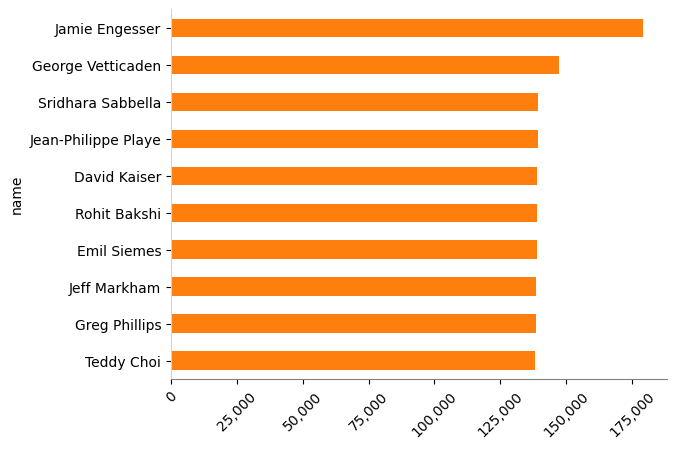

In [43]:
#creacion de un grafico 
# La columna 'name' pasa a ser el nombre de las filas

top_10 = top_10.set_index("name")

# Paleta de colores:
#  tab:blue     tab:red        tab:pink
#  tab:orange   tab:purple     tab:gray
#  tab:green    tab:brown      tab:olive
#  tab:cyan

top_10["miles-logged"].plot.barh(color="tab:orange", alpha=1)

plt.gca().invert_yaxis()

plt.gca().get_xaxis().set_major_formatter(
    matplotlib.ticker.FuncFormatter(lambda x, p: format(int(x), ","))
)

plt.xticks(rotation=45)

plt.gca().spines["left"].set_color("lightgray")
plt.gca().spines["bottom"].set_color("gray")
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.savefig("../submission/top10_drivers.png", bbox_inches="tight")

In [ ]:
# Conexión a la base de datos SQLite y almacena las tablas

connection = sqlite3.connect("../temp/db.sqlite")

drivers.to_sql("drivers_raw", connection, if_exists="replace", index=False)
timesheet.to_sql("timesheet_raw", connection, if_exists="replace", index=False)


# Crea vistas para las tablas drivers y timesheet

connection.executescript(
    """
    DROP VIEW IF EXISTS drivers;
    DROP VIEW IF EXISTS timesheet;

    CREATE VIEW drivers AS
    SELECT
        driverId AS driver_id,
        name,
        ssn,
        location,
        certified,
        "wage-plan" AS wage_plan
    FROM drivers_raw;

    CREATE VIEW timesheet AS
    SELECT
        driverId AS driver_id,
        week,
        "hours-logged" AS hours_logged,
        "miles-logged" AS miles_logged
    FROM timesheet_raw;
    """
)

connection.commit()
